# Y.Afisha User Behavior, Sales and Marketing Analysis

## Introduction

This project analyzes user activity, sales, and marketing expenses for Y.Afisha.

The main objective is to evaluate product usage, customer purchasing behavior, and the effectiveness of different marketing channels.

The analysis will focus on:

- user activity and retention;
- purchasing behavior and customer lifetime value;
- marketing expenses and user acquisition costs;
- return on marketing investment;
- differences between devices and advertising sources.

The final goal is to identify which marketing sources provide the best business performance and recommend where the marketing budget should be allocated.

## Table of Contents

1. Introduction
2. Data Description
3. Data Preprocessing

- 3.1 Data Types
- 3.2 Missing Values
- 3.3 Duplicates

   
4. Product Analysis

- 4.1 Daily, Weekly and Monthly Active Users
- 4.2 Sessions per Day
- 4.3 Session Duration
- 4.4 User Retention
     
   
5. Sales Analysis
   
- 5.1 Time to First Purchase
- 5.2 Number of Orders per Customer
- 5.3 Orders Over Time
- 5.4 Average Purchase Size
- 5.5 Customer Lifetime Value (LTV)


6. Marketing Analysis
   
- 6.1 Marketing Costs
- 6.2 Acquisition Cost per User and Paying Customer
- 6.3 Return on Marketing Investment (ROMI)
     
   
7. Analysis by Device and Marketing Source

- 7.1 Metrics by Device
- 7.2 Metrics by Marketing Source

    
8. Key Findings
9. Marketing Recommendations
10. Conclusion

## 2. Data Description

The analysis uses three datasets:

- `visits_log_us` contains one row per user session, including the user identifier, device, session start and end timestamps, and advertising source.
- `orders_log_us` contains one row per order, including the customer identifier, purchase timestamp, and revenue generated.
- `costs_us` contains daily marketing expenses for each advertising source.

The visits dataset is used to analyze product activity and acquisition sources, the orders dataset is used to evaluate purchasing behavior and customer value, and the costs dataset is used to calculate cost per acquired user and ROMI.

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the datasets into pandas DataFrames
visits_log_us = pd.read_csv('data/visits_log_us.csv')
orders_log_us = pd.read_csv('data/orders_log_us.csv')
costs_us = pd.read_csv('data/costs_us.csv')


In [3]:
# Check the dimensions of each dataset
print(visits_log_us.shape)
print(orders_log_us.shape)
print(costs_us.shape)

(359400, 5)
(50415, 3)
(2542, 3)


### Initial Data Overview

- The visits dataset contains 359,400 rows and 5 columns.
- The orders dataset contains 50,415 rows and 3 columns.
- The costs dataset contains 2,542 rows and 3 columns.

In [4]:
# Check the general information and data types
print(visits_log_us.info())
print(orders_log_us.info())
print(costs_us.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 13.7+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   50415 non-null  object 
 1   Revenue  50415 non-null  float64
 2   Uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 1.2+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     -------------- 

### Initial Observations

- All three datasets appear to have no missing values.
- The date and time columns are currently stored as `object` and need to be converted to `datetime`.
- The remaining numerical and categorical columns have appropriate data types for the analysis.

In [5]:
# Display the first rows of each dataset
print(visits_log_us.head(5))
print(orders_log_us.head(5))
print(costs_us.head(5))

    Device               End Ts  ...             Start Ts                   Uid
0    touch  2017-12-20 17:38:00  ...  2017-12-20 17:20:00  16879256277535980062
1  desktop  2018-02-19 17:21:00  ...  2018-02-19 16:53:00    104060357244891740
2    touch  2017-07-01 01:54:00  ...  2017-07-01 01:54:00   7459035603376831527
3  desktop  2018-05-20 11:23:00  ...  2018-05-20 10:59:00  16174680259334210214
4  desktop  2017-12-27 14:06:00  ...  2017-12-27 14:06:00   9969694820036681168

[5 rows x 5 columns]
                Buy Ts  Revenue                   Uid
0  2017-06-01 00:10:00    17.00  10329302124590727494
1  2017-06-01 00:25:00     0.55  11627257723692907447
2  2017-06-01 00:27:00     0.37  17903680561304213844
3  2017-06-01 00:29:00     0.55  16109239769442553005
4  2017-06-01 07:58:00     0.37  14200605875248379450
   source_id          dt  costs
0          1  2017-06-01  75.20
1          1  2017-06-02  62.25
2          1  2017-06-03  36.53
3          1  2017-06-04  55.00
4          1  

The initial inspection shows that the datasets are structured consistently with their descriptions. Date and time columns are stored as strings and will need to be converted to datetime format before the analysis.

## 3. Data Preprocessing

Before starting the analysis, the datasets will be prepared to ensure data quality and consistency. This step includes checking missing values and duplicates, correcting data types, and preparing the columns required for further analysis.

### 3.1 Data Types

In [6]:
# Convert date and time columns to datetime format
visits_log_us['Start Ts'] = pd.to_datetime(visits_log_us['Start Ts'])
visits_log_us['End Ts'] = pd.to_datetime(visits_log_us['End Ts'])
orders_log_us['Buy Ts'] = pd.to_datetime(orders_log_us['Buy Ts'])
costs_us['dt'] = pd.to_datetime(costs_us['dt'])


In [7]:
# Verify the updated data types
print(visits_log_us.info())
print(orders_log_us.info())
print(costs_us.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Device     359400 non-null  object        
 1   End Ts     359400 non-null  datetime64[ns]
 2   Source Id  359400 non-null  int64         
 3   Start Ts   359400 non-null  datetime64[ns]
 4   Uid        359400 non-null  uint64        
dtypes: datetime64[ns](2), int64(1), object(1), uint64(1)
memory usage: 13.7+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Buy Ts   50415 non-null  datetime64[ns]
 1   Revenue  50415 non-null  float64       
 2   Uid      50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entri

The date and time columns were successfully converted to the `datetime` format, making them suitable for further analysis.

### 3.2 Missing Values

In [8]:
# Check for missing values in each dataset
print(visits_log_us.isna().sum())
print(orders_log_us.isna().sum())
print(costs_us.isna().sum())

Device       0
End Ts       0
Source Id    0
Start Ts     0
Uid          0
dtype: int64
Buy Ts     0
Revenue    0
Uid        0
dtype: int64
source_id    0
dt           0
costs        0
dtype: int64


No missing values were found in any of the three datasets, so no further treatment is required.

### 3.3 Duplicates

In [9]:
# Check for duplicate rows in each dataset
print(visits_log_us.duplicated().sum())
print(orders_log_us.duplicated().sum())
print(costs_us.duplicated().sum())

0
0
0


No duplicate rows were found in any of the three datasets.

## 4. Product Analysis

This section analyzes how users interact with the product, focusing on user activity, session frequency, session duration, and retention.

### 4.1 Daily, Weekly and Monthly Active Users

Active user metrics are used to evaluate user engagement over different time periods. 
Daily Active Users (DAU), Weekly Active Users (WAU), and Monthly Active Users (MAU) help measure how frequently users interact with the platform and provide insights into overall product usage.

In [10]:
# Extract the session date from the session start timestamp
visits_log_us['session_date'] = visits_log_us['Start Ts'].dt.date

In [11]:
# Calculate the number of unique active users per day
dau = visits_log_us.groupby('session_date')['Uid'].nunique()

print(dau)

session_date
2017-06-01     605
2017-06-02     608
2017-06-03     445
2017-06-04     476
2017-06-05     820
              ... 
2018-05-27     620
2018-05-28    1039
2018-05-29     948
2018-05-30    1289
2018-05-31    1997
Name: Uid, Length: 364, dtype: int64


In [12]:
# Calculate the average number of daily active users
dau_total = dau.mean()
print(round(dau_total))

908


In [13]:
# Use ISO year and week together so weeks spanning New Year stay consistent
visits_log_us['session_year'] = visits_log_us['Start Ts'].dt.year
visits_log_us['session_month'] = visits_log_us['Start Ts'].dt.month
visits_log_us['session_iso_year'] = visits_log_us['Start Ts'].dt.isocalendar().year
visits_log_us['session_week'] = visits_log_us['Start Ts'].dt.isocalendar().week

In [14]:
# Calculate the number of unique active users per week
wau = visits_log_us.groupby(
    ['session_iso_year', 'session_week'])['Uid'].nunique()

print(wau)

session_iso_year  session_week
2017              22               2021
                  23               4129
                  24               2812
                  25               2878
                  26               3064
                  27               3294
                  28               4355
                  29               3841
                  30               2655
                  31               2364
                  32               2444
                  33               2746
                  34               3116
                  35               3694
                  36               4412
                  37               4319
                  38               4874
                  39               6241
                  40               7612
                  41               7074
                  42               7148
                  43               7401
                  44               7480
                  45               7179
         

In [15]:
# Calculate the average number of weekly active users
wau_total = wau.mean()
print(round(wau_total))

5716


In [16]:
# Calculate the number of unique active users per month
mau = visits_log_us.groupby(
    ['session_year',
     'session_month'])['Uid'].nunique()

print(mau)

session_year  session_month
2017          6                13259
              7                14183
              8                11631
              9                18975
              10               29692
              11               32797
              12               31557
2018          1                28716
              2                28749
              3                27473
              4                21008
              5                20701
Name: Uid, dtype: int64


In [17]:
# Calculate the average number of monthly active users
mau_total = mau.mean()
print(round(mau_total))

23228


### Findings

On average, the platform had approximately:

- **908 daily active users (DAU)**
- **5,716 weekly active users (WAU)**
- **23,228 monthly active users (MAU)**

These results provide an overview of user activity across daily, weekly, and monthly periods.

### 4.2 Sessions per Day

Session frequency helps understand how often users interact with the platform. Since one user can generate multiple sessions, this metric provides a broader view of user activity.

In [18]:
# Calculate the number of sessions per day
sessions_per_day = visits_log_us.groupby('session_date')['Uid'].count()
avg_sessions_per_day = sessions_per_day.mean()
print(round(avg_sessions_per_day))

987


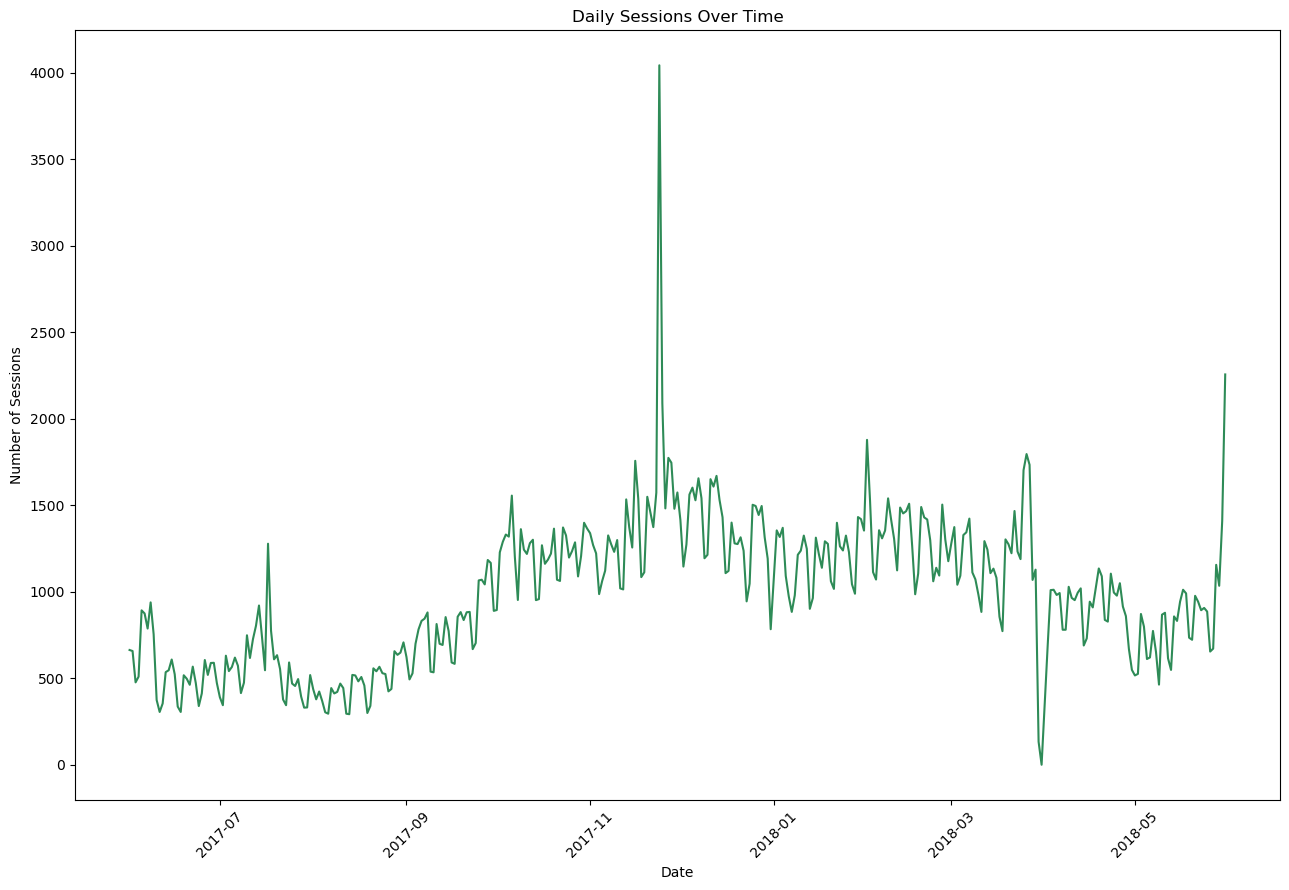

In [19]:
# Plot the number of sessions per day
sessions_per_day.plot(
    figsize=(13, 9),
    color='seagreen'
)

plt.title('Daily Sessions Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Sessions')
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

In [20]:
# Identify the highest number of daily sessions and its date
print(sessions_per_day.max())
print(sessions_per_day.idxmax())

4042
2017-11-24


In [21]:

# Identify the lowest number of daily sessions and its date
print(sessions_per_day.min())
print(sessions_per_day.idxmin())


1
2018-03-31


### Findings

The platform recorded an average of approximately **987 sessions per day**. Daily activity varied considerably throughout the analyzed period.

The highest activity occurred on **November 24, 2017**, with **4,042 sessions**. Since this date coincided with **Black Friday**, seasonal shopping behavior or promotional activity may have contributed to the increase.

The lowest activity occurred on **March 31, 2018**, with only **1 session**, which is highly unusual compared with the surrounding days and may indicate an anomaly or a possible data collection issue.

Further investigation would be necessary to confirm the causes of these unusual values.

### 4.3 Session Duration

Session duration analysis helps evaluate how long users remain engaged during each visit. Since session lengths can vary significantly, both distribution and statistical measures are analyzed.

In [22]:
# Calculate the duration of each session in seconds
visits_log_us['session_duration_sec'] = (
    visits_log_us['End Ts'] - visits_log_us['Start Ts']
).dt.total_seconds()

visits_log_us['session_duration_sec'].head()

# Invalid negative durations cannot represent time spent in a session.
# Keep the sessions for activity counts, but exclude their durations.
invalid_durations = visits_log_us['session_duration_sec'] < 0
print('Negative durations excluded:', int(invalid_durations.sum()))
visits_log_us.loc[invalid_durations, 'session_duration_sec'] = float('nan')


Negative durations excluded: 2


#### Session Duration Distribution

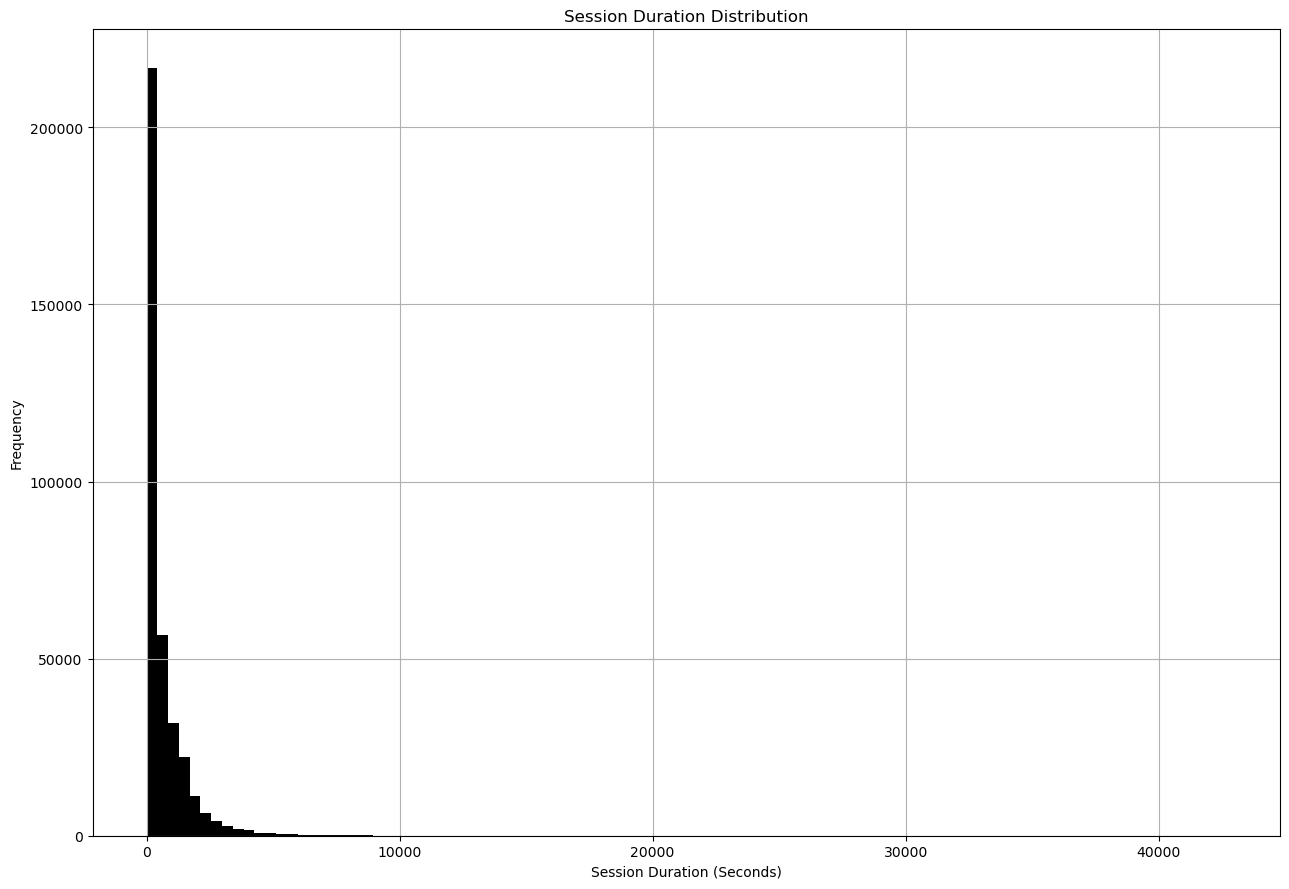

In [23]:
# Plot the distribution of session durations
visits_log_us['session_duration_sec'].hist(
    bins = 100,
    color = 'black',
    figsize = (13,9)
)
plt.title('Session Duration Distribution')
plt.xlabel('Session Duration (Seconds)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [24]:
# Calculate the most common session duration
session_duration_mode = visits_log_us['session_duration_sec'].mode()
print(session_duration_mode)

0    60.0
Name: session_duration_sec, dtype: float64


In [25]:
# Calculate the average session duration
session_duration_mean = visits_log_us['session_duration_sec'].mean()
print(session_duration_mean)

643.0422873805642


In [26]:
# Calculate the median session duration
session_duration_median = visits_log_us['session_duration_sec'].median()
print(session_duration_median)

300.0


### Findings

Session durations are strongly right-skewed, with most sessions concentrated at shorter durations and a small number of very long sessions.

The average session duration is approximately **643 seconds (10.7 minutes)**, while the median is **300 seconds (5 minutes)** and the most common duration is **60 seconds (1 minute)**.

The large difference between the mean, median, and mode confirms that long sessions are pulling the average upward. Therefore, the mean alone does not accurately represent a typical user session.

### 4.4 User Retention

Retention analysis evaluates whether users return after their first interaction with the platform. Users are grouped into monthly cohorts based on their first session date to measure long-term engagement.

In [27]:
# Find the first session date for each user
first_session = visits_log_us.groupby('Uid')['Start Ts'].min()
print(first_session)

Uid
11863502262781         2018-03-01 17:27:00
49537067089222         2018-02-06 15:55:00
297729379853735        2017-06-07 18:47:00
313578113262317        2017-09-18 22:49:00
325320750514679        2017-09-30 14:29:00
                               ...        
18446403737806311543   2017-11-30 03:36:00
18446424184725333426   2017-12-06 20:32:00
18446556406699109058   2018-01-01 16:29:00
18446621818809592527   2017-12-27 13:27:00
18446676030785672386   2017-10-04 16:01:00
Name: Start Ts, Length: 228169, dtype: datetime64[ns]


In [28]:
# Add the first session date for each user
visits_log_us['first_session_date'] = visits_log_us['Uid'].map(first_session)

# Create monthly acquisition cohorts
visits_log_us['first_session_month'] = (
    visits_log_us['first_session_date'].dt.to_period('M')
)

print(visits_log_us['first_session_month'])

0         2017-12
1         2018-02
2         2017-07
3         2018-03
4         2017-12
           ...   
359395    2017-07
359396    2018-01
359397    2018-03
359398    2017-11
359399    2017-09
Name: first_session_month, Length: 359400, dtype: period[M]


In [29]:
# Create the month of each session
visits_log_us['session_month_period'] = (
    visits_log_us['Start Ts'].dt.to_period('M')
)

print(visits_log_us['session_month_period'].head())

0    2017-12
1    2018-02
2    2017-07
3    2018-05
4    2017-12
Name: session_month_period, dtype: period[M]


In [30]:
# Calculate the cohort lifetime in months
visits_log_us['cohort_lifetime'] = (
    visits_log_us['session_month_period'] -
    visits_log_us['first_session_month']
).apply(lambda x: x.n)

visits_log_us[['first_session_month',
              'session_month', 'cohort_lifetime']].head()

Out[30]: 
  first_session_month  session_month  cohort_lifetime
0             2017-12             12                0
1             2018-02              2                0
2             2017-07              7                0
3             2018-03              5                2
4             2017-12             12                0


In [31]:
# Calculate the number of returning users for each cohort lifetime
retention = visits_log_us.groupby(
    ['first_session_month', 'cohort_lifetime']
)['Uid'].nunique()

retention.head()

Out[31]: 
first_session_month  cohort_lifetime
2017-06              0                  13259
                     1                   1043
                     2                    713
                     3                    814
                     4                    909
Name: Uid, dtype: int64


In [32]:
# Create a cohort retention table
retention_table = retention.unstack('cohort_lifetime')
retention_table.head()

Out[32]: 
cohort_lifetime           0       1       2   ...     9      10     11
first_session_month                           ...                     
2017-06              13259.0  1043.0   713.0  ...  674.0  539.0  596.0
2017-07              13140.0   737.0   674.0  ...  376.0  361.0    NaN
2017-08              10181.0   783.0   640.0  ...  265.0    NaN    NaN
2017-09              16704.0  1428.0  1156.0  ...    NaN    NaN    NaN
2017-10              25977.0  2042.0  1357.0  ...    NaN    NaN    NaN

[5 rows x 12 columns]


In [33]:
# Calculate retention rates for each cohort

retention_rate = retention_table.div(
    retention_table.iloc[:, 0],
    axis=0
)

# Convert retention rates to percentage values
retention_rate = retention_rate * 100

retention_rate.head()

Out[33]: 
cohort_lifetime         0         1         2   ...        9         10       11
first_session_month                             ...                             
2017-06              100.0  7.866355  5.377479  ...  5.083340  4.065163  4.49506
2017-07              100.0  5.608828  5.129376  ...  2.861492  2.747336      NaN
2017-08              100.0  7.690797  6.286219  ...  2.602888       NaN      NaN
2017-09              100.0  8.548851  6.920498  ...       NaN       NaN      NaN
2017-10              100.0  7.860800  5.223852  ...       NaN       NaN      NaN

[5 rows x 12 columns]


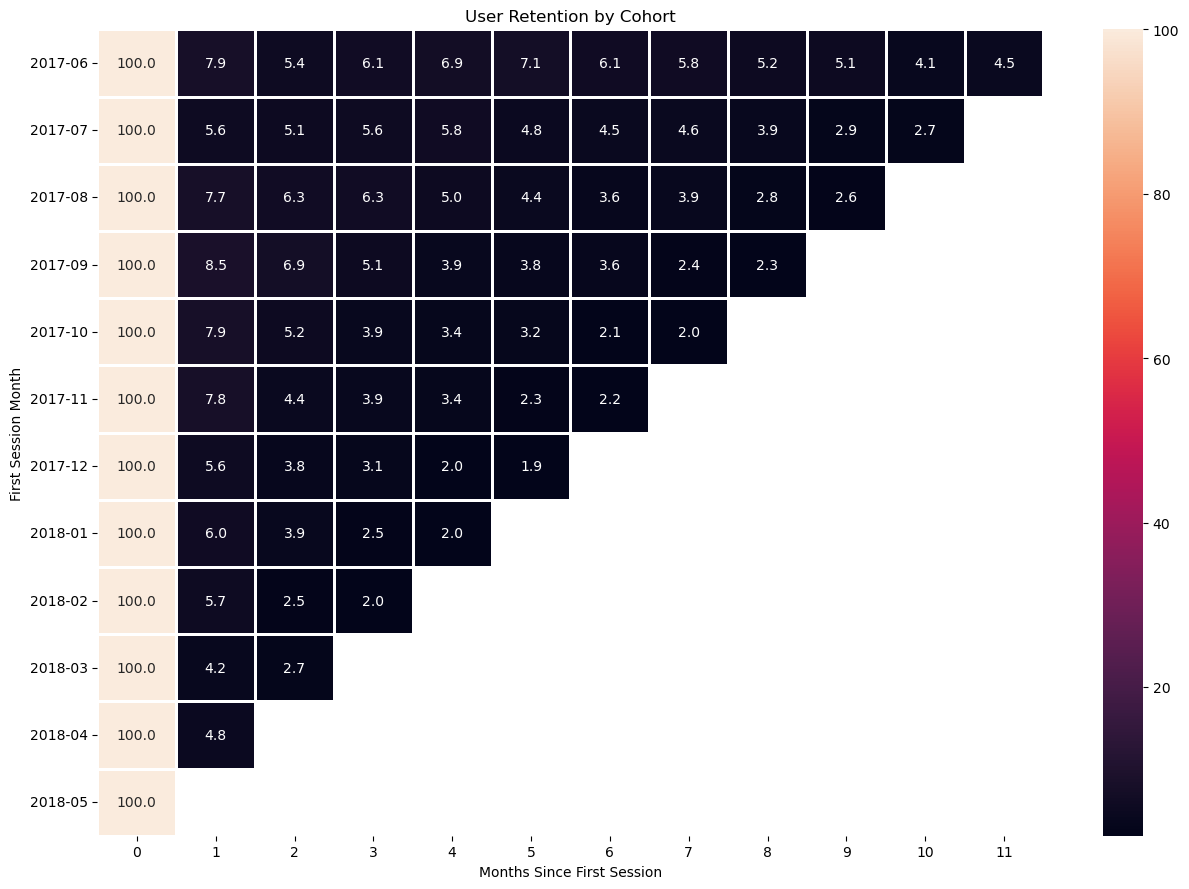

In [34]:
# Visualize cohort retention using a heatmap
plt.figure(figsize=(13,9))

sns.heatmap(
    retention_rate,
    annot = True,
    fmt = '.1f',
    linewidths = 1
)

plt.title('User Retention by Cohort')
plt.xlabel('Months Since First Session')
plt.ylabel('First Session Month')

plt.tight_layout()
plt.show()

### Findings

The retention analysis shows that most users do not return frequently after their first session. While all cohorts start with 100% retention in the acquisition month, retention drops significantly after the first month, reaching approximately 4–8%.

Over the following months, retention remains relatively low, generally between 2–6%, indicating that only a small proportion of users continue using the platform over time.

The earliest cohorts show slightly higher long-term retention compared with some later cohorts, suggesting that user engagement may have changed over the analyzed period.

Later cohorts have shorter observation windows. Acquisition-month activity is 100% by definition, and age-matched comparisons are needed before attributing differences to changing engagement.

## 5. Sales Analysis

### 5.1 Time to First Purchase

Understanding the time between the first user interaction and the first purchase helps evaluate the customer conversion process and identify how quickly users become customers.

In [35]:
# Find the first visit date for each user
first_visit = visits_log_us.groupby('Uid')['Start Ts'].min()
first_visit = first_visit.reset_index()

first_visit.head()

Out[35]: 
               Uid            Start Ts
0   11863502262781 2018-03-01 17:27:00
1   49537067089222 2018-02-06 15:55:00
2  297729379853735 2017-06-07 18:47:00
3  313578113262317 2017-09-18 22:49:00
4  325320750514679 2017-09-30 14:29:00


In [36]:
# Find the first purchase date for each customer
first_purchase = orders_log_us.groupby('Uid')['Buy Ts'].min()
first_purchase = first_purchase.reset_index()

first_purchase.head()

Out[36]: 
                Uid              Buy Ts
0   313578113262317 2018-01-03 21:51:00
1  1575281904278712 2017-06-03 10:13:00
2  2429014661409475 2017-10-11 18:33:00
3  2464366381792757 2018-01-28 15:54:00
4  2551852515556206 2017-11-24 10:14:00


In [37]:
# Merge first visit and first purchase data
conversion_time = first_visit.merge(
    first_purchase,
    on = 'Uid'
)

conversion_time.head()

Out[37]: 
                Uid            Start Ts              Buy Ts
0   313578113262317 2017-09-18 22:49:00 2018-01-03 21:51:00
1  1575281904278712 2017-06-03 10:13:00 2017-06-03 10:13:00
2  2429014661409475 2017-10-11 17:14:00 2017-10-11 18:33:00
3  2464366381792757 2018-01-27 20:10:00 2018-01-28 15:54:00
4  2551852515556206 2017-11-24 10:14:00 2017-11-24 10:14:00


In [38]:

# Calculate the number of days between first visit and first purchase
conversion_time['conversion_days'] = (
    conversion_time['Buy Ts'] - conversion_time['Start Ts']
).dt.days

# Calculate the average time to first purchase
avg_conversion_time = conversion_time['conversion_days'].mean()

print(avg_conversion_time)

# Calculate the median time to first purchase
median_conversion_time = conversion_time['conversion_days'].median()

print(median_conversion_time)

16.7298688497659
0.0


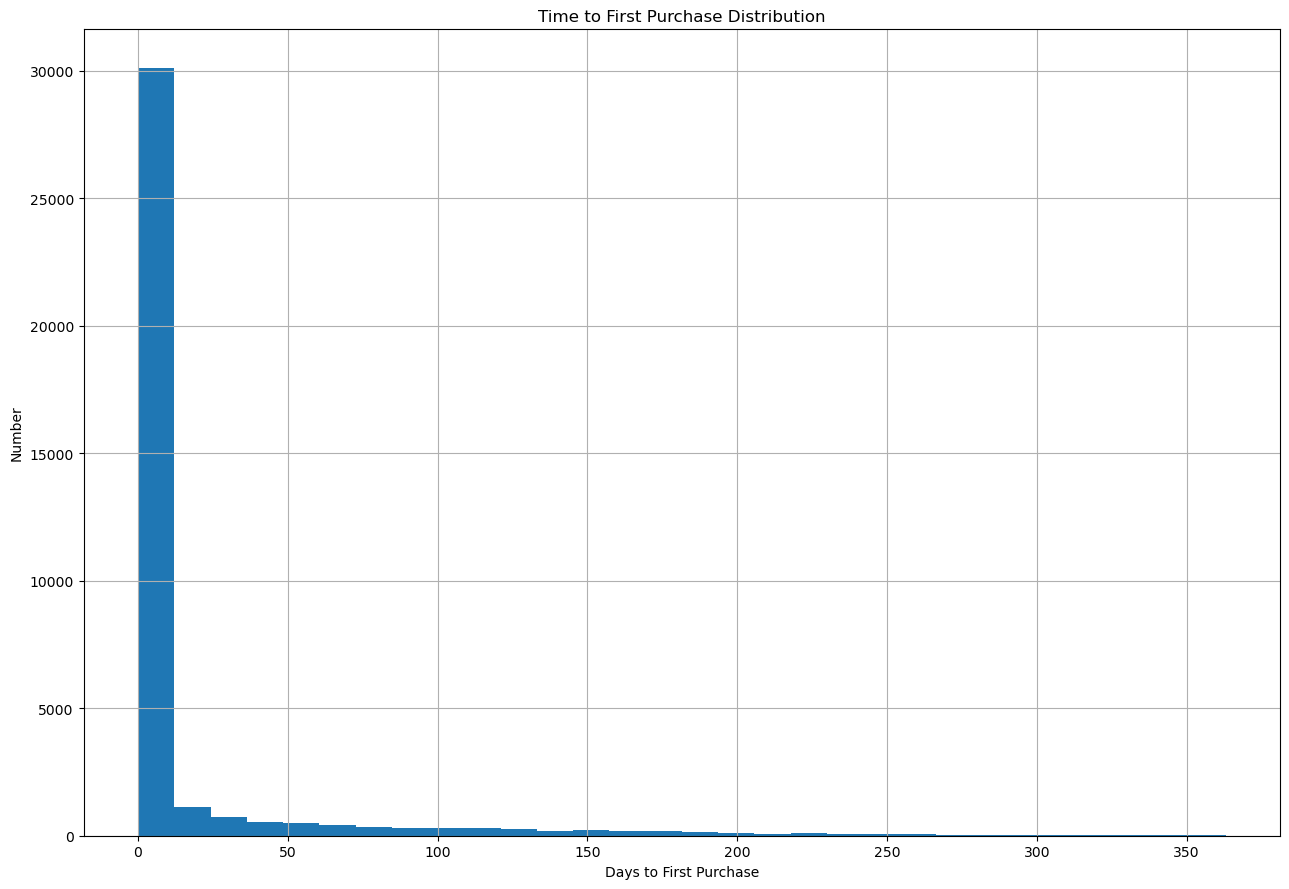

In [39]:
# Plot the distribution of time to first purchase

conversion_time['conversion_days'].hist(
    bins = 30,
    figsize=(13,9)
)

plt.title('Time to First Purchase Distribution')
plt.xlabel('Days to First Purchase')
plt.ylabel('Number')

plt.tight_layout()
plt.show()

In [40]:
# Calculate the percentage of customers who made their first purchase within the first day
first_day_conversion = (conversion_time['conversion_days'] == 0).mean()

print(first_day_conversion)

# Convert the same-day conversion rate to percentage
first_day_conversion = first_day_conversion * 100

print(first_day_conversion)


0.7218191276729732
72.18191276729732


### Findings

The majority of customers make their first purchase shortly after their initial visit. Approximately **72.18% of customers made their first purchase within 24 hours**, and the median conversion time is **0 days**.

However, the average time to first purchase is approximately **16.73 days**. The large difference between the mean and median is explained by the strongly right-skewed distribution, with a smaller group of customers taking considerably longer to make their first purchase.

Therefore, the median and the proportion of customers converting within the first day provide a more representative view of typical conversion behavior than the mean alone.


### 5.2 Number of Orders per Customer

Analyzing the number of orders per customer helps understand purchasing frequency and whether customers tend to make repeated purchases.

In [41]:
# Calculate the number of orders per customer
orders_per_customer = orders_log_us.groupby('Uid')['Buy Ts'].count()

print(orders_per_customer)

Uid
313578113262317         1
1575281904278712        2
2429014661409475        1
2464366381792757        1
2551852515556206        2
                       ..
18445147675727495770    1
18445407535914413204    3
18445601152732270159    1
18446156210226471712    1
18446167067214817906    1
Name: Buy Ts, Length: 36523, dtype: int64


In [42]:
# Calculate the average number of orders per customer
avg_orders_per_customer = orders_per_customer.mean()

print(avg_orders_per_customer)

# Calculate the median number of orders per customer
median_orders_per_customer = orders_per_customer.median()

print(median_orders_per_customer)

1.3803630588943954
1.0


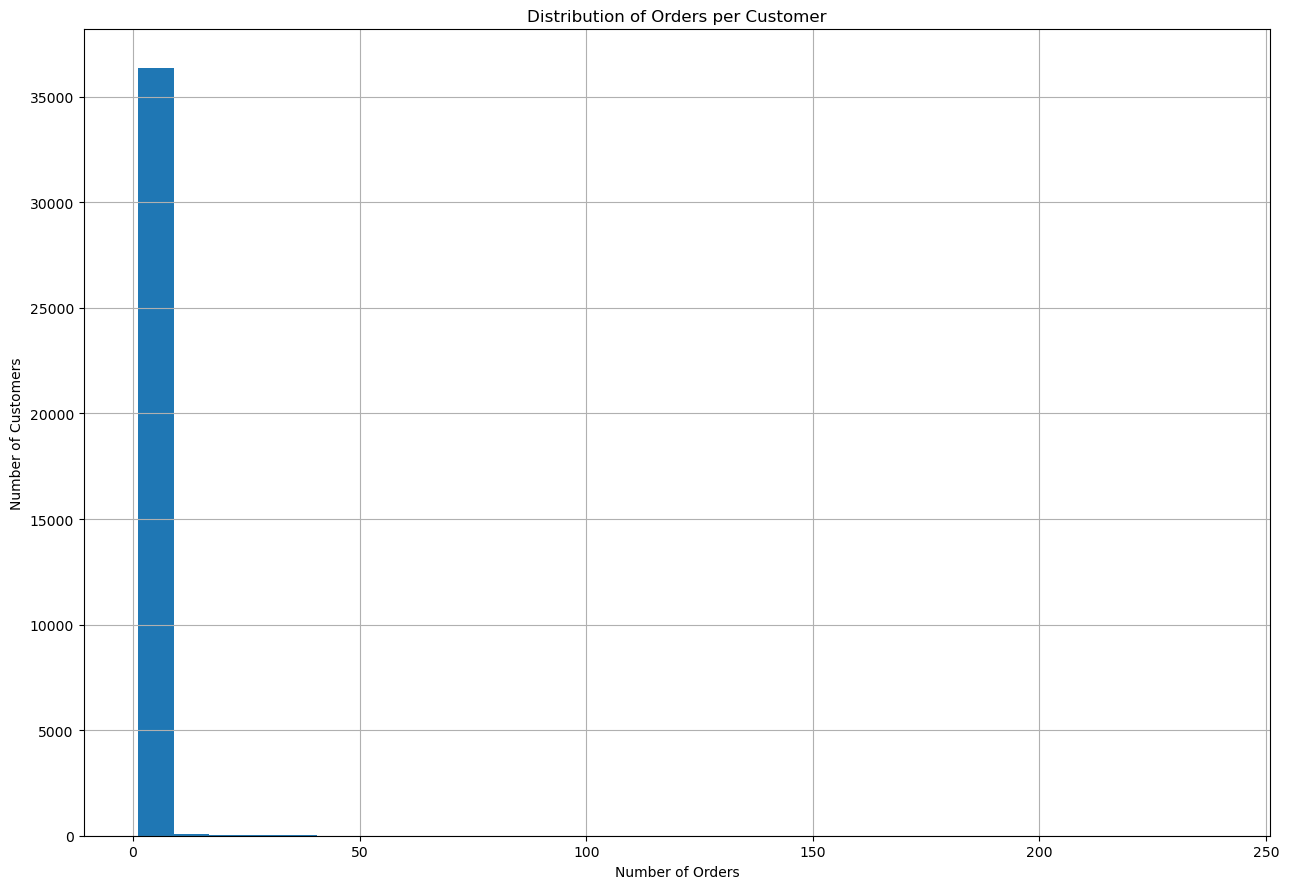

In [43]:
# Plot the distribution of orders per customer
orders_per_customer.hist(
    bins= 30,
    figsize=(13,9)
)

plt.title('Distribution of Orders per Customer')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [44]:
# Identify the maximum number of orders made by a customer
max_orders = orders_per_customer.max()

print(max_orders)

# Identify the customer with the highest number of orders
customer_max_orders = orders_per_customer.idxmax()

print(customer_max_orders)

239
3644482766749211722


In [45]:
# Count customers by number of orders
order_frequency = orders_per_customer.value_counts().sort_index()

order_frequency.head(10)

Out[45]: 
Buy Ts
1     30231
2      4395
3      1086
4       375
5       147
6        79
7        41
8        24
9         7
10       15
Name: count, dtype: int64


In [46]:
# Calculate the percentage of customers who made only one order
one_order_percentage = (
    order_frequency[1] / orders_per_customer.count()
) * 100

print(one_order_percentage)

82.77249952084988


### Findings

Customers made an average of approximately **1.38 orders**, while the median was **1 order**.

Most customers purchased only once: **82.77% of customers made exactly one order** during the analyzed period. The distribution is strongly right-skewed, with only a small proportion of customers making repeated purchases.

A notable extreme case was identified, with one customer making **239 orders**. This explains why the average is slightly higher than the median.

Overall, the results indicate that repeat purchasing is relatively limited, as the majority of customers do not make a second purchase.

### 5.3 Orders Over Time

Analyzing the number of orders over time helps identify changes in purchasing activity, seasonal patterns, and periods of higher customer demand.


In [47]:
# Calculate the number of orders per month
orders_log_us['order_month'] = (
    orders_log_us['Buy Ts'].dt.to_period('M')
)

orders_per_month = orders_log_us.groupby(
    'order_month'
).size()


print(orders_per_month)

order_month
2017-06    2354
2017-07    2363
2017-08    1807
2017-09    3387
2017-10    5679
2017-11    5659
2017-12    6218
2018-01    4721
2018-02    5281
2018-03    5326
2018-04    3273
2018-05    4346
2018-06       1
Freq: M, dtype: int64


In [48]:
# Exclude the incomplete month of June 2018
orders_per_month_complete = orders_per_month[
    orders_per_month.index < pd.Period('2018-06', freq='M')
]

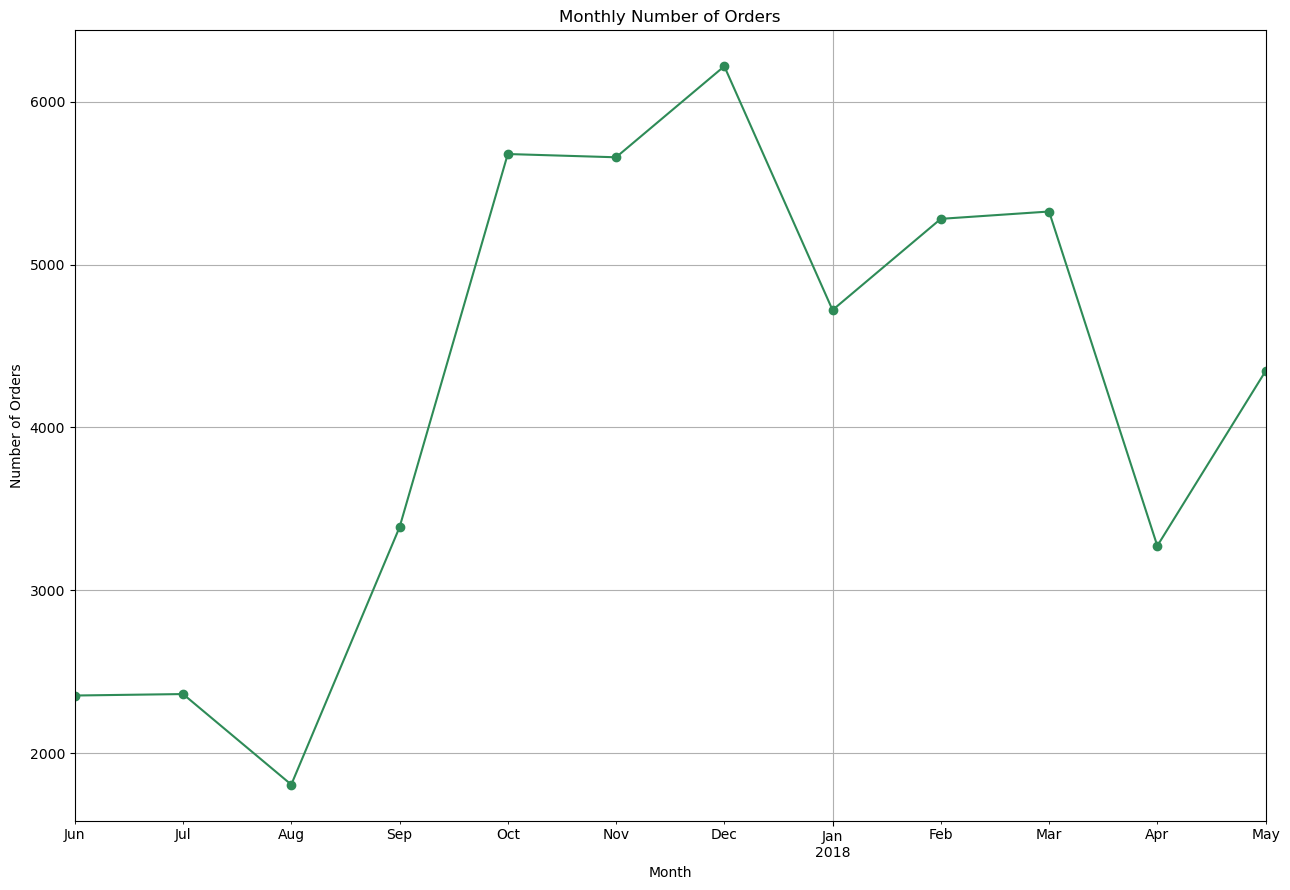

In [49]:
# Plot the number of orders per month

orders_per_month_complete.plot(
    kind='line',
    figsize=(13, 9),
    marker='o',
    color='seagreen'
)

plt.title('Monthly Number of Orders')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.grid()

plt.tight_layout()
plt.show()

### Findings

The number of monthly orders varied considerably throughout the analyzed period. Purchasing activity increased strongly from August 2017, rising from **1,807 orders** to **5,679 orders in October 2017**.

The highest number of orders was recorded in **December 2017, with 6,218 orders**, indicating particularly strong customer demand near the end of the year.

After the December peak, the number of orders declined to **4,721 in January 2018**, recovered moderately in February and March, and then fell again in April. May showed another increase, reaching **4,346 orders**.

The isolated order recorded in June 2018 was excluded from the graph because June represents an incomplete observation period and would create a misleading comparison with complete months.

Overall, purchasing activity was strongest between October 2017 and March 2018, although monthly order volume showed considerable fluctuations.

### 5.4 Average Purchase Size


In [50]:
# Calculate the average purchase size
average_purchase_size = orders_log_us['Revenue'].mean()

print(average_purchase_size)

# Calculate the median purchase size
median_purchase_size = orders_log_us['Revenue'].median()

print(median_purchase_size)

4.999646930477041
2.5


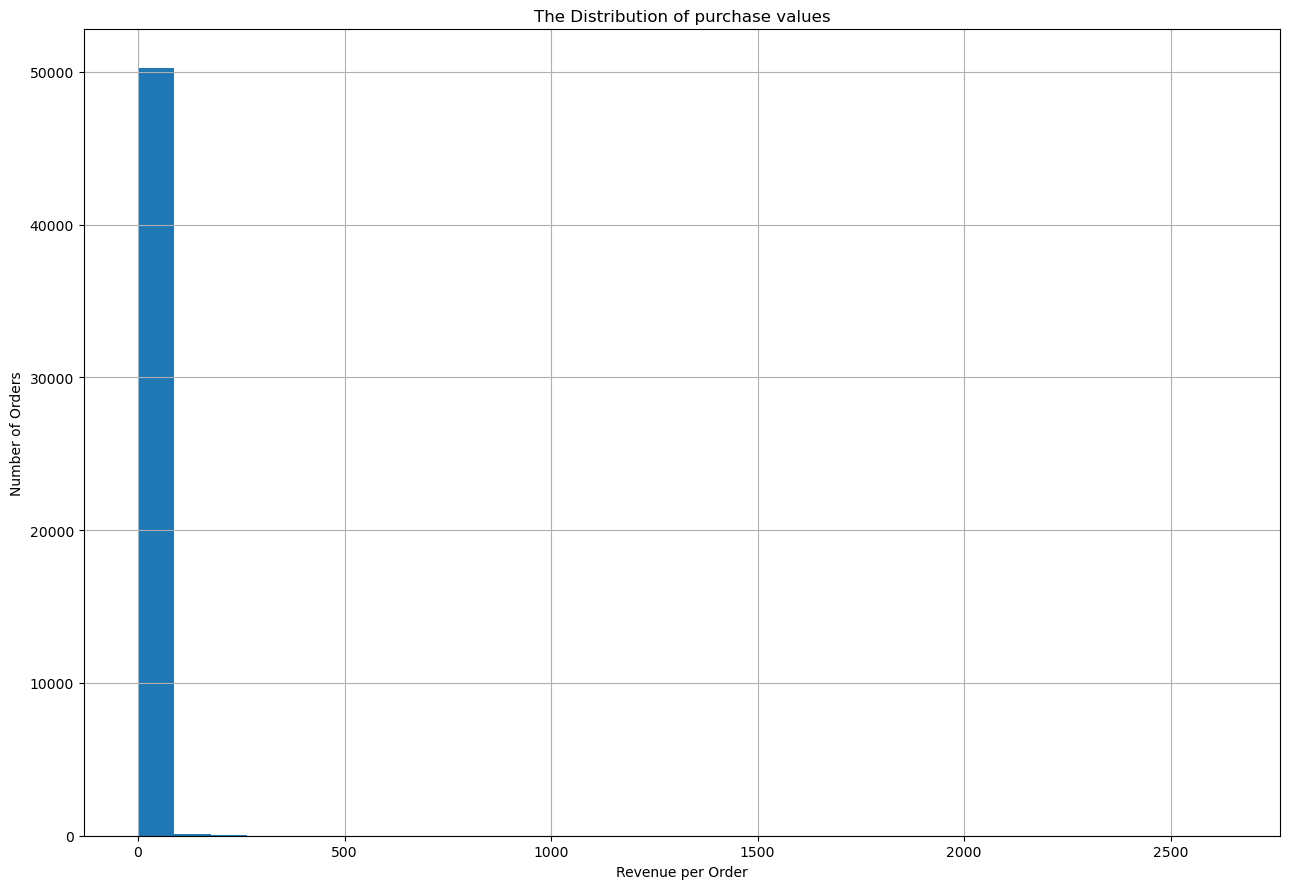

In [51]:
# Plot the distribution of purchase values
orders_log_us['Revenue'].hist(
    bins= 30,
    figsize=(13,9)
)

plt.title('The Distribution of purchase values')
plt.xlabel('Revenue per Order')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

In [52]:
# Identify the highest purchase value
max_purchase = orders_log_us['Revenue'].max()

print(max_purchase)

2633.28


### Findings

The average purchase value is approximately **5.00**, while the median is **2.50**, indicating that a typical purchase tends to be relatively small.

The distribution is strongly right-skewed, with most orders concentrated at lower values and a small number of considerably larger purchases. The highest purchase value was **2633.28**, which helps explain why the average is higher than the median.

Therefore, the median provides a better representation of a typical purchase, while the mean is influenced by a small number of high-value orders.

### 5.5 Customer Lifetime Value (LTV)

Customer Lifetime Value (LTV) measures how much revenue customers generate over time. Cohort analysis will be used to evaluate how customer value develops after the first purchase.

Here, LTV is observed cumulative revenue per cohort buyer, not a forecast of full lifetime profit. Incomplete June 2018 revenue is excluded for every cohort in the comparison. Cohorts should be compared at the same age.

In [53]:
# Find the first purchase month for each customer
first_order_month = orders_log_us.groupby('Uid')['order_month'].min()
first_order_month.head()

Out[53]: 
Uid
313578113262317     2018-01
1575281904278712    2017-06
2429014661409475    2017-10
2464366381792757    2018-01
2551852515556206    2017-11
Name: order_month, dtype: period[M]


In [54]:
# Add the first purchase month to each order
orders_log_us['first_order_month'] = orders_log_us['Uid'].map(first_order_month)
orders_log_us[
    ['Uid', 'order_month', 'first_order_month']
    ].head(10)

Out[54]: 
                    Uid order_month first_order_month
0  10329302124590727494     2017-06           2017-06
1  11627257723692907447     2017-06           2017-06
2  17903680561304213844     2017-06           2017-06
3  16109239769442553005     2017-06           2017-06
4  14200605875248379450     2017-06           2017-06
5  10402394430196413321     2017-06           2017-06
6  12464626743129688638     2017-06           2017-06
7   3644482766749211722     2017-06           2017-06
8  17542070709969841479     2017-06           2017-06
9   1074355127080856382     2017-06           2017-06


In [55]:
# Calculate the number of customers in each cohort
cohort_sizes = orders_log_us.groupby('first_order_month')['Uid'].nunique()

print(cohort_sizes)

first_order_month
2017-06    2023
2017-07    1923
2017-08    1370
2017-09    2581
2017-10    4340
2017-11    4081
2017-12    4383
2018-01    3373
2018-02    3651
2018-03    3533
2018-04    2276
2018-05    2988
2018-06       1
Freq: M, Name: Uid, dtype: int64


In [56]:
# Calculate the cohort lifetime in months
orders_log_us['cohort_lifetime'] = (
    (orders_log_us['order_month'].dt.year -
    orders_log_us['first_order_month'].dt.year) * 12
    +
    (orders_log_us['order_month'].dt.month -
    orders_log_us['first_order_month'].dt.month)
)
orders_log_us[
    ['first_order_month', 'order_month', 'cohort_lifetime']
].head(10)


Out[56]: 
  first_order_month order_month  cohort_lifetime
0           2017-06     2017-06                0
1           2017-06     2017-06                0
2           2017-06     2017-06                0
3           2017-06     2017-06                0
4           2017-06     2017-06                0
5           2017-06     2017-06                0
6           2017-06     2017-06                0
7           2017-06     2017-06                0
8           2017-06     2017-06                0
9           2017-06     2017-06                0


In [57]:
# Calculate revenue by cohort and cohort lifetime
# Exclude incomplete June 2018 revenue for every cohort, not only new cohorts.
cohort_orders = orders_log_us[orders_log_us['Buy Ts'] < '2018-06-01']
cohort_revenue_lifetime = cohort_orders.groupby(
    ['first_order_month', 'cohort_lifetime']
)['Revenue'].sum()

cohort_revenue_lifetime.head()

Out[57]: 
first_order_month  cohort_lifetime
2017-06            0                  9557.49
                   1                   981.82
                   2                   885.34
                   3                  1931.30
                   4                  2068.58
Name: Revenue, dtype: float64


In [58]:
# Create a revenue table by cohort lifetime
cohort_revenue_lifetime_table = cohort_revenue_lifetime.unstack(
    'cohort_lifetime'
)

cohort_revenue_lifetime_table.head()

Out[58]: 
cohort_lifetime          0        1        2   ...       9        10      11
first_order_month                              ...                          
2017-06             9557.49   981.82   885.34  ...  1225.51  1155.66  519.62
2017-07            11557.65   644.61  1199.05  ...   282.96   299.36     NaN
2017-08             7228.83   646.63   628.12  ...   257.53      NaN     NaN
2017-09            14568.53  2884.49  1344.52  ...      NaN      NaN     NaN
2017-10            21716.20  2325.21   830.65  ...      NaN      NaN     NaN

[5 rows x 12 columns]


In [59]:
# Calculate revenue per customer by cohort lifetime
revenue_per_customer_lifetime = cohort_revenue_lifetime_table.div(
    cohort_sizes,
    axis=0
)

revenue_per_customer_lifetime.head()

Out[59]: 
cohort_lifetime          0         1         2   ...        9         10        11
first_order_month                                ...                              
2017-06            4.724414  0.485329  0.437637  ...  0.605788  0.571261  0.256856
2017-07            6.010218  0.335211  0.623531  ...  0.147145  0.155673       NaN
2017-08            5.276518  0.471993  0.458482  ...  0.187978       NaN       NaN
2017-09            5.644529  1.117586  0.520930  ...       NaN       NaN       NaN
2017-10            5.003733  0.535763  0.191394  ...       NaN       NaN       NaN

[5 rows x 12 columns]


In [60]:
# Calculate cumulative LTV for each cohort
ltv = revenue_per_customer_lifetime.cumsum(axis=1)

ltv.head()

Out[60]: 
cohort_lifetime          0         1   ...         10         11
first_order_month                      ...                      
2017-06            4.724414  5.209743  ...  11.622378  11.879234
2017-07            6.010218  6.345429  ...   8.386854        NaN
2017-08            5.276518  5.748511  ...        NaN        NaN
2017-09            5.644529  6.762115  ...        NaN        NaN
2017-10            5.003733  5.539495  ...        NaN        NaN

[5 rows x 12 columns]


In [61]:
# Exclude the incomplete June 2018 cohort

ltv_complete = ltv[
    ltv.index < pd.Period('2018-06', freq='M')
]

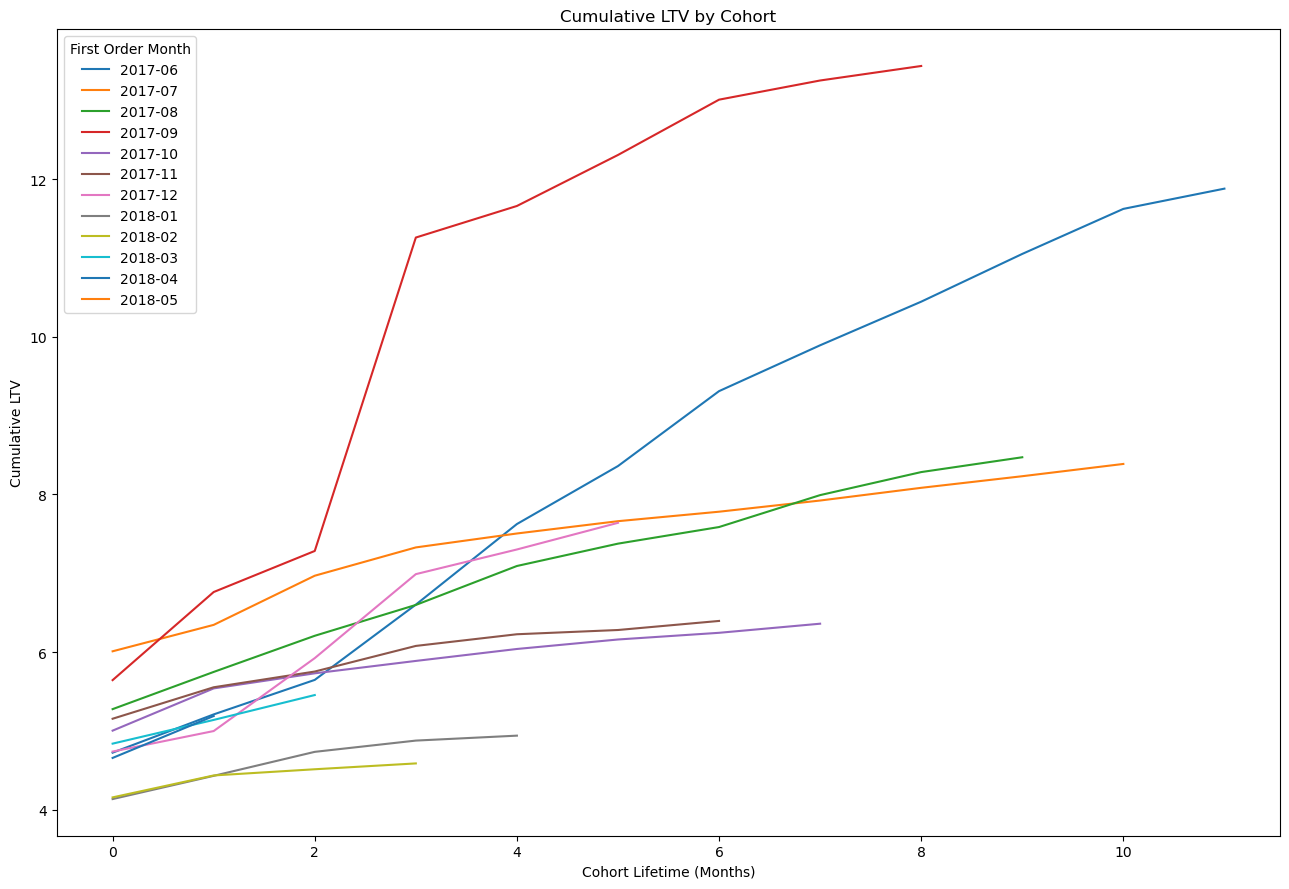

In [62]:
# Plot cumulative LTV by cohort
ltv_complete.T.plot(
    figsize=(13,9)
)

plt.title('Cumulative LTV by Cohort')
plt.xlabel('Cohort Lifetime (Months)')
plt.ylabel('Cumulative LTV')
plt.legend(title='First Order Month')

plt.tight_layout()
plt.show()

### Findings

The cumulative LTV analysis shows that customer value generally increases over time across the cohorts. The **September 2017 cohort showed the strongest growth**, reaching approximately **13.44 in cumulative LTV after eight months**.

The **June 2017 cohort also showed consistent long-term growth**, reaching approximately **11.88 after eleven months**. In comparison, most other cohorts showed more moderate increases in cumulative customer value over the observed period.

However, the more recent cohorts have shorter observation periods and therefore cannot yet be directly compared with older cohorts over the same lifetime.

Therefore, the results suggest that **customer lifetime value varies considerably between cohorts**, with some groups generating substantially more value over time than others.

## 6. Marketing Analysis

### 6.1 Marketing Costs

This section analyzes marketing expenses and customer acquisition performance across different sources.

The analysis focuses on marketing costs, user acquisition cost (cost per acquired user), and return on marketing investment (ROMI) to compare observed acquisition costs and revenue recovery across sources.

In [63]:
# Calculate the total marketing costs
total_marketing_costs = costs_us['costs'].sum()

print(total_marketing_costs)

329131.62


In [64]:
# Calculate total marketing costs by source
costs_by_source = costs_us.groupby('source_id')['costs'].sum()

print(costs_by_source)

source_id
1      20833.27
2      42806.04
3     141321.63
4      61073.60
5      51757.10
9       5517.49
10      5822.49
Name: costs, dtype: float64


In [65]:
# Extract the month of each marketing expense
costs_us['cost_month'] = costs_us['dt'].dt.to_period('M')

costs_us['cost_month'].head()

Out[65]: 
0    2017-06
1    2017-06
2    2017-06
3    2017-06
4    2017-06
Name: cost_month, dtype: period[M]


In [66]:
# Calculate total marketing costs by month
monthly_marketing_costs = costs_us.groupby('cost_month')['costs'].sum()

print(monthly_marketing_costs)

cost_month
2017-06    18015.00
2017-07    18240.59
2017-08    14790.54
2017-09    24368.91
2017-10    36322.88
2017-11    37907.88
2017-12    38315.35
2018-01    33518.52
2018-02    32723.03
2018-03    30415.27
2018-04    22289.38
2018-05    22224.27
Freq: M, Name: costs, dtype: float64


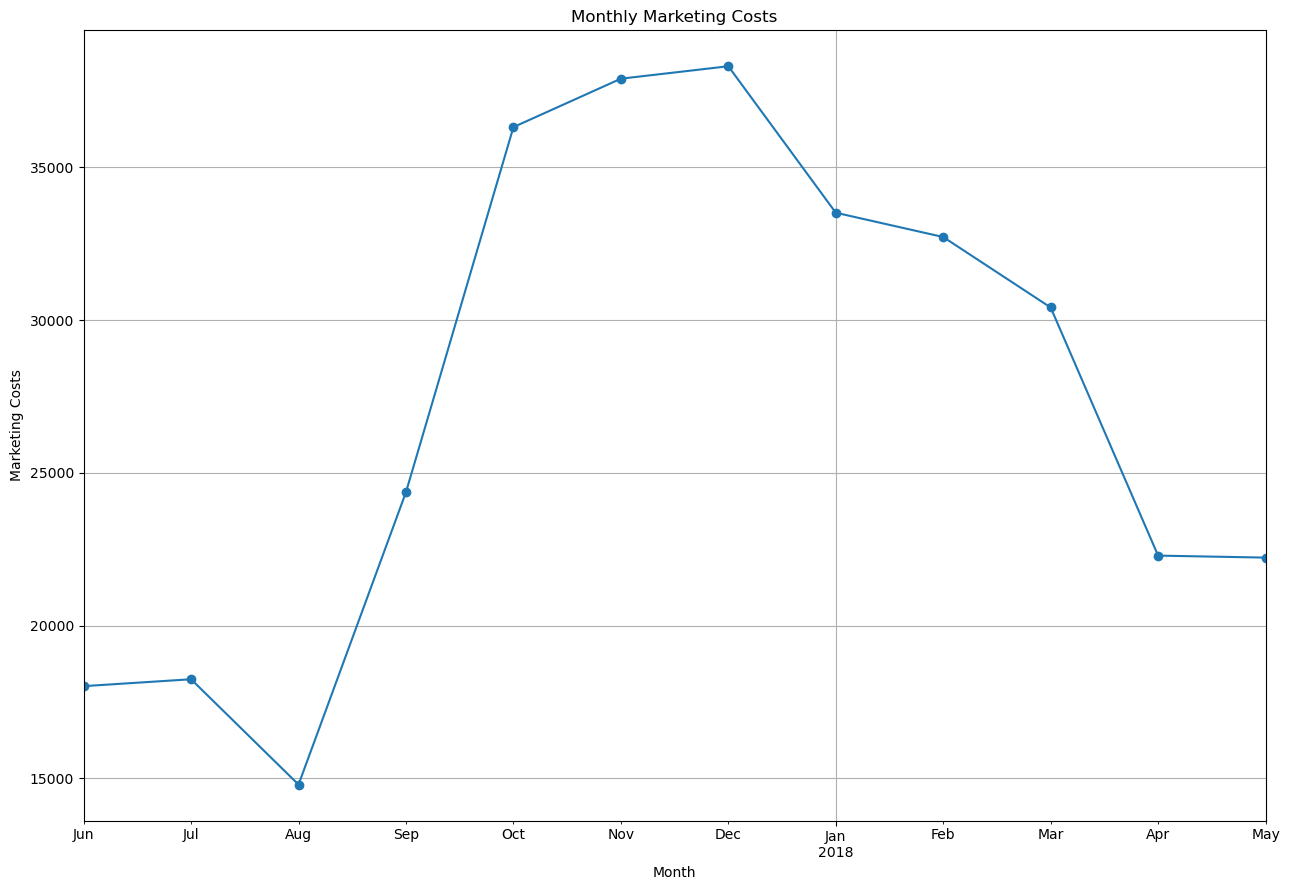

In [67]:
# Plot monthly marketing costs
monthly_marketing_costs.plot(
    kind='line',
    figsize=(13,9),
    marker='o'
)

plt.title('Monthly Marketing Costs')
plt.xlabel('Month')
plt.ylabel('Marketing Costs')
plt.grid()

plt.tight_layout()
plt.show()

### Findings

Total marketing expenses during the analyzed period amounted to **329,131.62**. Among the acquisition sources, **source 3 received the highest investment, with 141,321.63**, followed by sources 4 and 5.

Marketing spending also varied considerably over time. Monthly costs increased substantially from September 2017 and reached their highest level in **December 2017, at 38,315.35**.

After this peak, marketing expenses gradually declined, reaching approximately **22,224.27 in May 2018**.

Therefore, marketing investment was concentrated both in specific acquisition sources and in the period between October and December 2017. However, marketing costs alone are not sufficient to evaluate performance, so the next analysis will compare these expenses with customer acquisition and revenue.

### 6.2 Acquisition Cost per User and Paying Customer

Cost per acquired user divides source spending by all users first observed through that source. Paying-customer CAC instead divides spending by unique buyers attributed to that source. These metrics answer different questions and should not be used interchangeably.

Attribution uses one first-observed session per user. One user has tied first-session timestamps; original row order is the deterministic tie-breaker. This is an observed first-touch convention, not proof of the channel that caused acquisition. Figures pool the observation window and are not acquisition-cohort-matched CAC.

In [68]:
# Select one first-observed source per user for consistent attribution.
# Stable sorting keeps the original row order as the tie-breaker.
first_sessions = (
    visits_log_us.sort_values('Start Ts', kind='stable')
    .drop_duplicates('Uid', keep='first')
)
assert first_sessions['Uid'].is_unique
first_sessions.head()

Out[68]: 
         Device              End Ts  ...  session_month_period cohort_lifetime
308527  desktop 2017-06-01 00:02:00  ...               2017-06               0
245715  desktop 2017-06-01 00:16:00  ...               2017-06               0
260646  desktop 2017-06-01 00:02:00  ...               2017-06               0
235930  desktop 2017-06-01 00:04:00  ...               2017-06               0
11727   desktop 2017-06-01 00:11:00  ...               2017-06               0

[5 rows x 15 columns]


In [69]:
# Calculate the number of new users by source
users_by_source = first_sessions.groupby('Source Id')['Uid'].nunique()

print(users_by_source)

Source Id
1      9469
2     17616
3     66116
4     72346
5     49237
6         2
7        32
9      6448
10     6903
Name: Uid, dtype: int64


In [70]:
# Cost per acquired user includes users who never purchased.
cac_by_source = costs_by_source / users_by_source
print('Cost per acquired user:')
print(cac_by_source)

# Paying-customer CAC uses unique buyers, attributed by first observed source.
buyers_by_source = first_sessions[
    first_sessions['Uid'].isin(orders_log_us['Uid'])
].groupby('Source Id')['Uid'].nunique()
paying_customer_cac = costs_by_source / buyers_by_source
print('Cost per paying customer:')
print(paying_customer_cac)

Cost per acquired user:
1     2.200155
2     2.429952
3     2.137480
4     0.844188
5     1.051183
6          NaN
7          NaN
9     0.855690
10    0.843472
dtype: float64
Cost per paying customer:
1      7.186364
2     12.209367
3     13.493901
4      5.931779
5      7.467479
7           NaN
9      5.071222
10     4.381106
dtype: float64


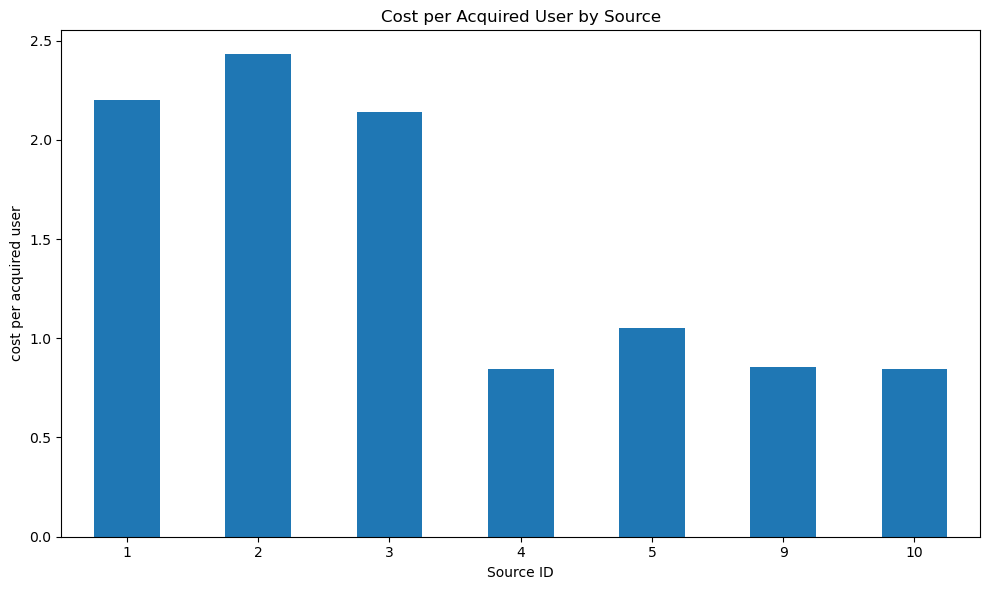

In [71]:
# Plot user acquisition cost by source
cac_by_source.dropna().plot(
    kind = 'bar',
    figsize=(10,6)
)

plt.title('Cost per Acquired User by Source')
plt.xlabel('Source ID')
plt.ylabel('cost per acquired user')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Findings

User acquisition cost varies considerably across marketing sources. **Source 2 has the highest cost per acquired user, at approximately 2.43 per acquired user**, followed by sources 1 and 3, with cost per acquired user values of approximately **2.20 and 2.14**, respectively.

In contrast, **sources 4 and 10 have the lowest acquisition costs**, at approximately **0.84 per user**, while source 9 also shows a relatively low cost per acquired user of approximately **0.86**.

Sources 6 and 7 were not included in the cost per acquired user comparison because no corresponding marketing costs were available for these sources.

Therefore, sources 4, 9, and 10 appear to acquire users more cost-efficiently. However, a lower acquisition cost does not necessarily indicate higher profitability, so marketing costs must also be compared with the revenue generated by acquired customers.

Using unique buyers instead, paying-customer CAC is approximately 7.19 for source 1, 12.21 for source 2, 13.49 for source 3, 5.93 for source 4, 7.47 for source 5, 5.07 for source 9, and 4.38 for source 10. These are pooled-window acquisition costs, not maturity-adjusted cohort estimates.

### 6.3 Revenue-Based Return on Marketing Spend

The metric called ROMI below is `(attributed revenue − marketing cost) / marketing cost`. Without gross margin, fulfillment costs, and incremental attribution, this is a revenue-based proxy rather than profit ROI. A positive value means observed attributed revenue exceeds advertising spend, not that the channel is profitable.

Spend and visits cover June 2017–May 2018; the supplied orders include a short boundary period on June 1, 2018. Source totals preserve the supplied orders, while cohort LTV charts exclude incomplete June revenue. Older acquisitions have longer to generate revenue, so source totals are not maturity-adjusted or causal channel comparisons.

In [72]:
# Select one acquisition source for each user
user_sources = first_sessions[
    ['Uid', 'Source Id']
]

user_sources_unique = user_sources.drop_duplicates(
    subset='Uid'
)

user_sources_unique.head()

Out[72]: 
                         Uid  Source Id
308527  13890188992670018146          5
245715  16706502037388497502          3
260646  16152015161748786004          3
235930   8842918131297115663          3
11727   10329302124590727494          1


In [73]:
# Preserve every order and verify the attribution join is many-to-one.
orders_with_source = orders_log_us.merge(
    user_sources_unique, on='Uid', how='left',
    validate='many_to_one', indicator=True
)
assert len(orders_with_source) == len(orders_log_us)
assert orders_with_source['_merge'].eq('both').all()
orders_with_source.head()

Out[73]: 
               Buy Ts  Revenue  ...  Source Id _merge
0 2017-06-01 00:10:00    17.00  ...          1   both
1 2017-06-01 00:25:00     0.55  ...          2   both
2 2017-06-01 00:27:00     0.37  ...          2   both
3 2017-06-01 00:29:00     0.55  ...          2   both
4 2017-06-01 07:58:00     0.37  ...          3   both

[5 rows x 8 columns]


In [74]:
# Check missing acquisition sources after the merge

orders_with_source['Source Id'].isna().sum()

Out[74]: np.int64(0)


In [75]:
# Calculate total revenue by acquisition source
revenue_by_source = orders_with_source.groupby('Source Id')['Revenue'].sum()

print(revenue_by_source)

Source Id
1     31090.55
2     46923.61
3     54511.24
4     56696.83
5     52624.02
7         1.22
9      5759.40
10     4450.33
Name: Revenue, dtype: float64


In [76]:
# Calculate ROMI by acquisition source
romi_by_source = (
    revenue_by_source - costs_by_source
) / costs_by_source

print(romi_by_source)

1     0.492351
2     0.096191
3    -0.614275
4    -0.071664
5     0.016750
7          NaN
9     0.043844
10   -0.235665
dtype: float64


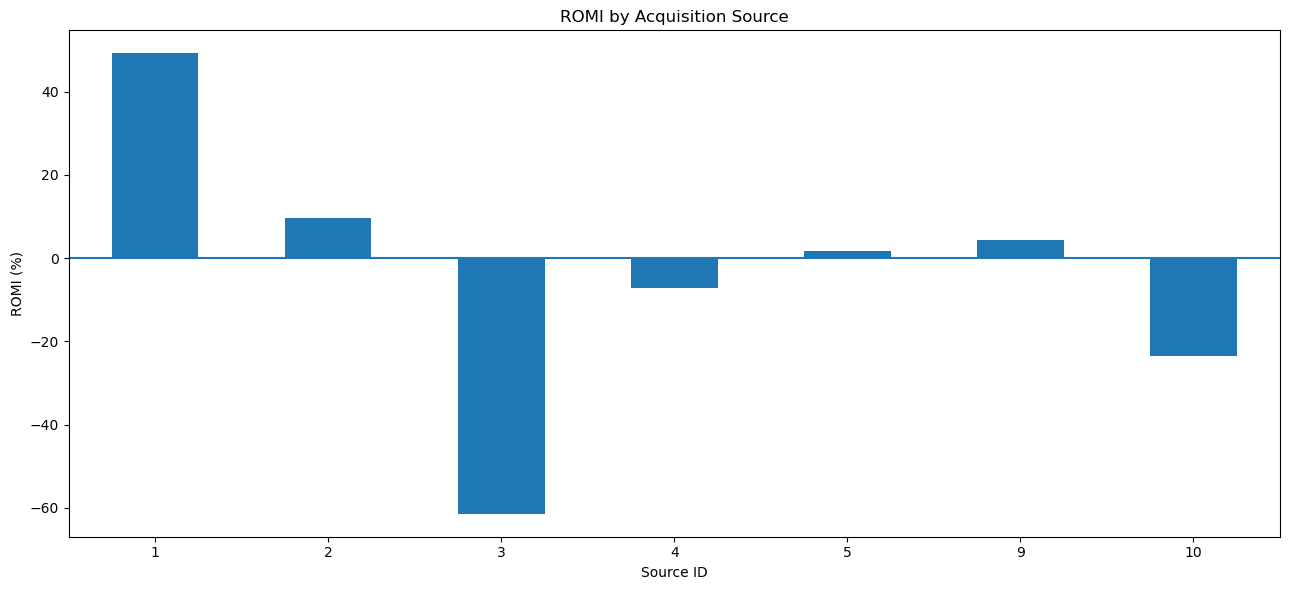

In [77]:
# Plot ROMI by acquisition source
(romi_by_source.dropna() * 100).plot(
    kind=('bar'),
    figsize=(13,6)
)

plt.title('ROMI by Acquisition Source')
plt.xlabel('Source ID')
plt.ylabel('ROMI (%)')
plt.axhline(0)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Findings

ROMI varies considerably across acquisition sources. **Source 1 achieved the highest ROMI, at approximately 49.24%**, indicating the strongest return on marketing investment among the analyzed sources.

Sources 2, 5, and 9 also generated positive revenue-based returns, with ROMI values of approximately **9.62%, 1.68%, and 4.38%**, respectively. In contrast, sources 3, 4, and 10 generated negative returns.

**Source 3 showed the weakest performance, with a ROMI of approximately -61.43%**, despite receiving the highest marketing investment. Source 10 also had a negative ROMI of approximately **-23.57%**, even though it had one of the lowest user acquisition costs.

Therefore, a low cost per acquired user does not necessarily result in a high marketing return. **Source 1 appears to provide the strongest overall return, while Source 3 may require a reassessment of marketing spending and acquisition strategy.**

These ROMI values represent the cumulative return observed during the analyzed period. Since customers acquired earlier had more time to generate revenue, the results should be interpreted together with cohort maturity and the available observation window.

## 7. Analysis by Device and Marketing Source

This section compares key metrics across different devices and marketing sources to identify differences in user behavior and acquisition performance.

The analysis complements the previous product, sales, and marketing metrics by examining how performance varies between user segments.

### 7.1 Metrics by Device

User behavior may vary depending on the device used to access the platform. This section compares key product metrics between **desktop and touch users** to identify differences in engagement and usage patterns.

In [78]:
# Calculate the average session duration by device
avg_session_duration_by_device = visits_log_us.groupby(
    'Device'
)['session_duration_sec'].mean()

print(avg_session_duration_by_device)

Device
desktop    703.312041
touch      479.619407
Name: session_duration_sec, dtype: float64


In [79]:
# Calculate the number of unique users by device
users_by_device = visits_log_us.groupby('Device')['Uid'].nunique()

print(users_by_device)

Device
desktop    164523
touch       71345
Name: Uid, dtype: int64


In [80]:
# Calculate the number of sessions by device
sessions_by_device = visits_log_us.groupby('Device').size()

print(sessions_by_device)

Device
desktop    262567
touch       96833
dtype: int64


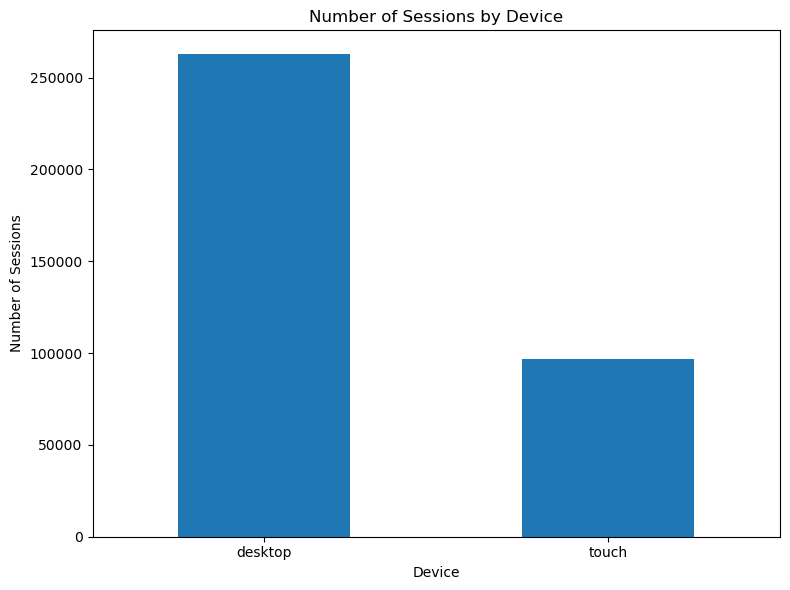

In [81]:
# Plot the number of sessions by device
sessions_by_device.plot(
    kind='bar',
    figsize=(8, 6)
)

plt.title('Number of Sessions by Device')
plt.xlabel('Device')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

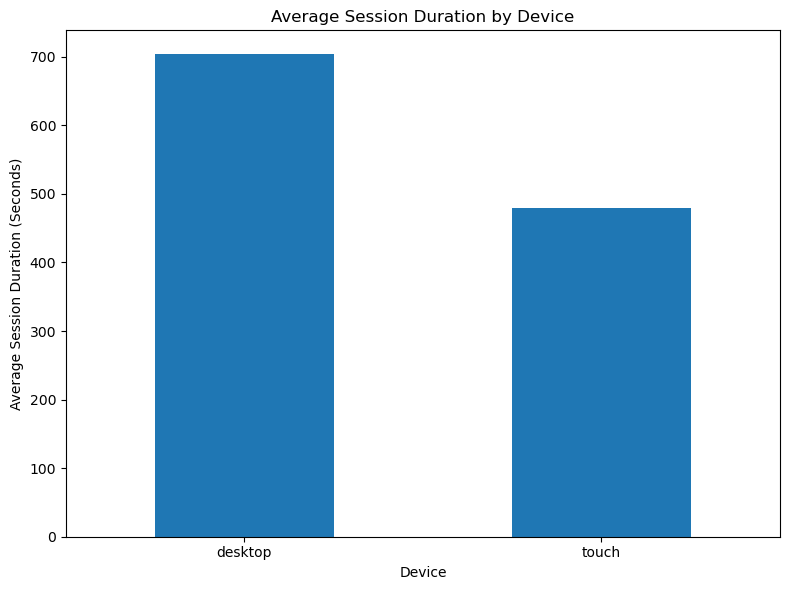

In [82]:
# Plot the average session duration by device
avg_session_duration_by_device.plot(
    kind='bar',
    figsize=(8, 6)
)

plt.title('Average Session Duration by Device')
plt.xlabel('Device')
plt.ylabel('Average Session Duration (Seconds)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Findings

Desktop users show higher levels of platform activity than touch users. The platform recorded **262,567 desktop sessions compared with 96,833 touch sessions**, while the number of unique users was **164,523 for desktop and 71,345 for touch**.

Session duration also differs between devices. Desktop sessions lasted approximately **703 seconds on average (11.7 minutes)**, compared with approximately **480 seconds (8.0 minutes)** for touch sessions.

Overall, **desktop is the dominant device in terms of both usage volume and session duration**, suggesting that desktop users tend to interact with the platform more extensively than touch users.

Users may appear on both devices; device-specific unique-user counts should not be added as mutually exclusive audiences. Session duration alone is not a measure of satisfaction.

### 7.2 Metrics by Marketing Source

Marketing sources may attract users with different behavior and value. This section compares key metrics across acquisition sources to evaluate their performance and support marketing investment decisions.

In [83]:
# Keep one acquisition source for each user
user_sources_unique = user_sources.drop_duplicates(
    subset='Uid'
)

# Create a mapping between each user and their acquisition source
acquisition_source_by_user = user_sources_unique.set_index(
    'Uid'
)['Source Id']

# Add the acquisition source to each session
visits_log_us['acquisition_source'] = visits_log_us[
    'Uid'
].map(acquisition_source_by_user)

# Calculate average session duration by acquisition source
avg_session_duration_by_source = visits_log_us.groupby(
    'acquisition_source'
)['session_duration_sec'].mean()


print(avg_session_duration_by_source)

acquisition_source
1     961.421841
2     858.832584
3     614.411570
4     574.599495
5     542.429904
6     510.000000
7     605.142857
9     597.824793
10    708.012192
Name: session_duration_sec, dtype: float64


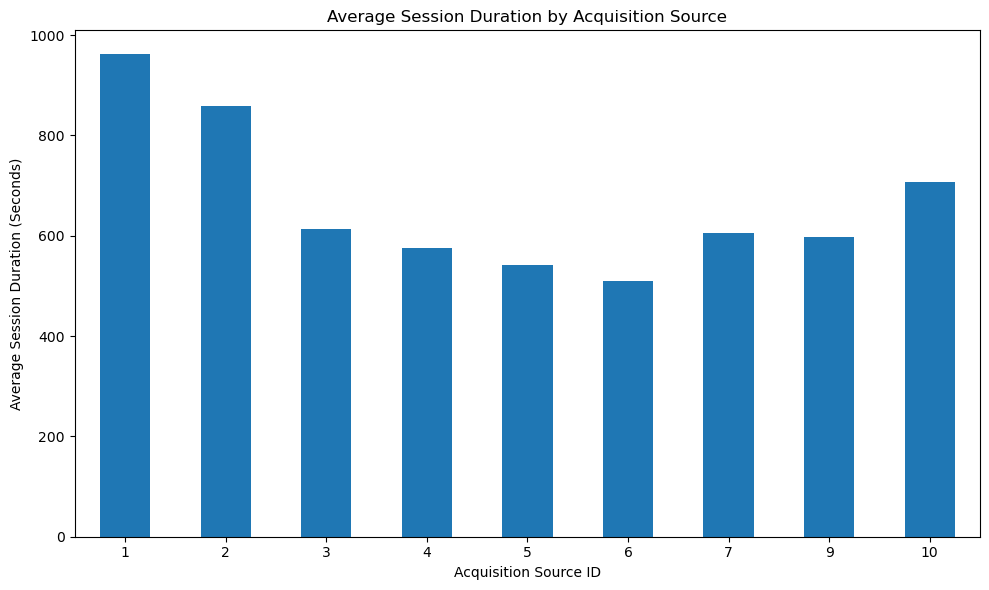

In [84]:
# Plot average session duration by acquisition source
avg_session_duration_by_source.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Session Duration by Acquisition Source')
plt.xlabel('Acquisition Source ID')
plt.ylabel('Average Session Duration (Seconds)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

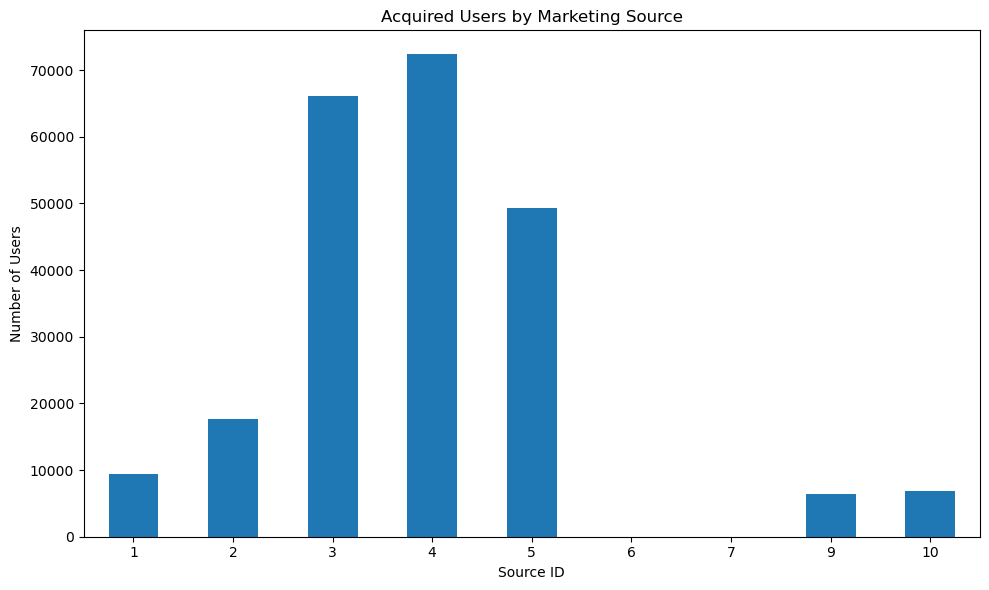

In [85]:
# Plot the number of acquired users by marketing source
users_by_source.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Acquired Users by Marketing Source')
plt.xlabel('Source ID')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Findings

User behavior and acquisition volume vary considerably across marketing sources. **Source 4 acquired the largest number of users (72,346)**, followed by Source 3 (66,116) and Source 5 (49,237).

However, higher acquisition volume does not necessarily correspond to stronger user engagement or marketing return. Users acquired through **Source 1 generated the longest average sessions, at approximately 961 seconds (16.0 minutes)**, and this source also achieved the highest ROMI (49.24%), despite acquiring fewer users than sources 3, 4, and 5.

Source 2 also attracted relatively engaged users, with an average session duration of approximately **859 seconds (14.3 minutes)**.

In contrast, Source 3 acquired a large number of users but showed a shorter average session duration of approximately **614 seconds** and the **lowest ROMI (-61.43%)**. This indicates that high acquisition volume alone did not translate into efficient marketing performance.

Sources 6 and 7 acquired very few users, so their engagement results are not sufficient for reliable performance conclusions.

Overall, marketing sources should be evaluated using a combination of **acquisition volume, user engagement, acquisition cost, and return on marketing investment**, rather than acquisition volume alone.

## 8. Key Findings

The analysis of Y.Afisha's product usage, sales performance, and marketing investments revealed several important patterns.

### Product Performance

- Desktop is the dominant platform, with **262,567 sessions and 164,523 unique users**, compared with 96,833 sessions and 71,345 unique users on touch devices.
- Desktop users also show stronger engagement, with an average session duration of approximately **703 seconds (11.7 minutes)** compared with **480 seconds (8.0 minutes)** for touch users.
- User activity and retention patterns indicate that engagement is strongest during the initial stages of the customer lifecycle and decreases over time.

### Sales Performance

- Customer conversion occurs quickly for most users. Approximately **72.18% of customers make their first purchase within 24 hours**, and the median conversion time is **0 days**.
- The average conversion time is considerably higher at **16.73 days**, indicating that a smaller group of customers takes much longer to make their first purchase.
- Cohort analysis shows substantial differences in customer value over time. Some cohorts accumulate significantly higher LTV than others, demonstrating that customer value cannot be evaluated based only on the initial purchase.

### Marketing Performance

- Marketing spending varies considerably across acquisition sources, with **Source 3 receiving the largest investment**.
- Acquisition cost also differs significantly. Sources **4, 9, and 10 have relatively low cost per acquired user**, while Sources 1, 2, and 3 are more expensive.
- However, low acquisition cost does not necessarily result in better observed revenue-to-spend performance. **Source 1 achieved the highest ROMI at approximately 49.24%**, despite having a relatively high cost per acquired user.
- **Source 3 recorded the lowest ROMI at approximately -61.43%**, even though it attracted a large number of users and received the highest marketing investment.
- Source 10 also demonstrates this trade-off: despite having one of the lowest cost per acquired user values, its ROMI was approximately **-23.57%**.

### Overall Insight

The results demonstrate that **acquisition volume and low cost per acquired user alone are not sufficient indicators of marketing success**. Marketing performance should be evaluated by combining acquisition cost, customer engagement, revenue generation, LTV, and ROMI.

Among the analyzed sources, **Source 1 shows the strongest overall observed revenue-to-spend performance**, while Source 3 represents the clearest opportunity for marketing budget optimization.

**Interpretation:** Source rankings are descriptive first-observed-touch revenue comparisons, not causal or profit-based investment results. The acquisition metric above counts all users; paying-customer CAC is separately reported in section 6.2.

## 9. Marketing Recommendations

### Investigate Source 3 first

Source 3 received the largest spend and has the weakest observed revenue-based return. Review targeting, attribution quality, acquisition-cohort maturity, and unit economics before deciding how much to reduce or reallocate.

### Test incremental investment in Source 1

Source 1 has the strongest observed revenue-to-spend result. This makes it a candidate for a controlled budget test, not proof that additional spending will achieve the same return. Measure marginal acquisition cost and contribution profit before scaling.

### Compare channels on equivalent observation windows

Use the same first-observed-source attribution for all metrics. Compare cohorts at the same age, distinguish cost per user from cost per paying customer, and incorporate gross margin. Monitor sources with low user-acquisition cost rather than assuming that low cost alone implies value.

### Improve repeat engagement

Most observed buyers purchase once. Test retention initiatives with measurable outcomes while recognizing the platform's event-driven use case and unequal customer observation periods.

## 10. Conclusion

This analysis connects product activity, customer purchasing behavior, acquisition cost, and observed revenue-based marketing return. Source 1 shows the strongest observed revenue-to-spend performance, while Source 3 receives the largest investment and warrants investigation.

The practical next step is to validate these differences with comparable cohort ages, contribution margins, and controlled budget tests. The current results are descriptive, not evidence of causal channel effectiveness or guaranteed profitability.

The portfolio edition retains the original analytical structure and adds consistent source attribution, explicit join checks, separate user and buyer acquisition costs, and data-quality and observation-window limitations.